In [1]:
import sys

In [2]:
!{sys.executable} -m pip install geopandas

In [3]:
import geopandas as gpd
from pathlib import Path

In [4]:
notebook_data_dir = Path("notebook_experimentation_data")
notebook_data_dir.mkdir(parents=True, exist_ok=True)

In [5]:
subcuencas = {
    "San Miguel": notebook_data_dir / "Subc_San_Miguel" / "RH09" / "RH09D" / "RH09De",
    "Río Sonora-Hillo": notebook_data_dir / "Subc_R_Son_Hillo" / "RH09" / "RH09D" / "RH09Da",
    "La Poza": notebook_data_dir / "Subc_La_Poza" / "RH09" / "RH09D" / "RH09Di",
    "La Manga": notebook_data_dir / "Subc_La_Manga" / "RH09" / "RH09E" / "RH09Eb",
}

## Informacion de los sufijos
El nombre de los archivos esta compuesto por la clave de la subcuenca y el sufijo “_hl” 
para líneas de flujo, “_dr” para puntos de drenaje y “_subc” para unidades de captación 
a nivel subcuenca. 

In [6]:
san_miguel_dr = gpd.read_file(
    subcuencas["San Miguel"] / "RH09De_dr.shp"
)

san_miguel_hl = gpd.read_file(
    subcuencas["San Miguel"] / "RH09De_hl.shp"
)

san_miguel_subc = gpd.read_file(
    subcuencas["San Miguel"] / "RH09De_subc.shp"
)

### Diccionario Líneas de Flujo
Archivos con terminacion "*_hl"

Aquí tienes la tabla transcrita en formato Markdown:

| Nombre | Tipo | Long | Descripción | Dominio de valores |
| --- | --- | --- | --- | --- |
| FID | OID |  |  | 0, ... N |
| SHAPE | Geometry |  | Geometría | Polyline |
| ID | Numérico | 11 | Identificador único | 1 ... N |
| CVE_SUBC | Caracter | 7 | Clave de la subcuenca |  |
| CLAVE50K | Caracter | 7 | Clave del conjunto topográfico escala 1:50000 |  |
| TIPO | Numérico | 11 | Tipo de entidad |  |
| ENTIDAD | Caracter | 17 | Entidad |  |
| FC | Numérico | 11 | Código de rasgo |  |
| CONDICION | Caracter | 13 | Condición de la corriente |  |
| EDICION | Caracter | 1 | Tipo de la línea "original" o "nueva" | 'O' ó 'N' |
| FECHA | Fecha | 8 | Para líneas originales: fecha en que se creó o actualizó el conjunto topográfico.<br> Para líneas nuevas: fecha de término de los trabajos de edición de la conectividad. | DD/MM/AAAA |
| LENGHTM | Numérico | 12.2 | Longitud del segmento |  |
| ID_DRENA | Numérico | 11 | Identificador del punto de drenaje al cual pertenece la línea | 1...N |
| FLOWDIR | Numérico | 11 | Definición de la dirección de flujo | 0 ó 1 |
| ENABLED | Numérico | 6 | Campo para habilitar o deshabilitar segmentos en redes geométricas | 0 ó 1 |
| DESC_ENABL | Caracter | 2 | Descripción del campo Enabled (Ciclo o bifurcación) | Nulo, 'C' o 'B' |
| CALI_REPR | Numérico | 11 | Calificador de representación geométrica | 0,1,2 ó 3 |
| SECUENCEID | Numérico | 8 | Identificador de secuencia |  |
| ORDER_1 | Numérico | 8 | Magnitud de orden (clasificación de Strahler) a nivel de subcuenca | N...1, -1 |
| LEVEL_1 | Numérico | 8 | Nivel de corriente a nivel de subcuenca | 1...N, -1 |
| ARBSUM_1 | Numérico | 12.2 | Sumatoria de longitudes de líneas de flujo aguas arriba a nivel de subcuenca |  |
| PATHL_1 | Numérico | 12.2 | Longitud de trayectoria (sumatoria de longitudes aguas abajo) a nivel de subcuenca |  |

In [7]:
san_miguel_hl.columns

Index(['ID', 'CVE_SUBC', 'CLAVE50K', 'TIPO', 'ENTIDAD', 'FC', 'CONDICION',
       'EDICION', 'FECHA', 'LENGTHM', 'ID_DRENA', 'FLOWDIR', 'ENABLED',
       'DESC_ENABL', 'CALI_REPR', 'SEQUENCEID', 'ORDER_1', 'LEVEL_1',
       'ARBSUM_1', 'PATHL_1', 'geometry'],
      dtype='str')

In [8]:
san_miguel_hl.head()

,ID,CVE_SUBC,CLAVE50K,TIPO,ENTIDAD,FC,CONDICION,EDICION,FECHA,LENGTHM,...,FLOWDIR,ENABLED,DESC_ENABL,CALI_REPR,SEQUENCEID,ORDER_1,LEVEL_1,ARBSUM_1,PATHL_1,geometry
0,3042476,RH09De,h12b82,101,CORRIENTE DE AGUA,3271,INTERMITENTE,O,2002-07-31,481.7230,...,1,1,NaN,0,16688.0,1,4,481.7230,184367.8967,"LINESTRING (-110.64526 30.22667, -110.64524 30..."
1,3042477,RH09De,h12d22,101,CORRIENTE DE AGUA,3271,INTERMITENTE,O,1999-11-30,412.0311,...,1,1,NaN,0,4813.0,1,4,412.0311,113510.2079,"LINESTRING (-110.53352 29.72567, -110.53346 29..."
2,3042478,RH09De,h12d12,101,CORRIENTE DE AGUA,3271,INTERMITENTE,O,1999-10-31,19.0431,...,1,1,NaN,0,5537.0,3,4,6380.2699,130538.5233,"LINESTRING (-110.41773 29.78281, -110.41772 29..."
3,3042479,RH09De,h12b82,101,CORRIENTE DE AGUA,3271,INTERMITENTE,O,2002-07-31,353.1103,...,1,1,NaN,0,10183.0,3,4,6625.6949,158369.5557,"LINESTRING (-110.55105 30.06227, -110.551 30.0..."
4,3042480,RH09De,h12b72,101,CORRIENTE DE AGUA,3271,INTERMITENTE,O,2002-08-31,795.3661,...,1,1,NaN,0,22031.0,1,3,795.3661,213387.3147,"LINESTRING (-110.62299 30.35346, -110.62304 30..."


In [9]:
san_miguel_hl.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 25838 entries, 0 to 25837
Data columns (total 21 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   ID          25838 non-null  int64         
 1   CVE_SUBC    25838 non-null  str           
 2   CLAVE50K    24975 non-null  str           
 3   TIPO        25838 non-null  int64         
 4   ENTIDAD     25838 non-null  str           
 5   FC          25838 non-null  int64         
 6   CONDICION   25838 non-null  str           
 7   EDICION     25838 non-null  str           
 8   FECHA       25838 non-null  datetime64[ms]
 9   LENGTHM     25838 non-null  float64       
 10  ID_DRENA    25838 non-null  int32         
 11  FLOWDIR     25838 non-null  int64         
 12  ENABLED     25838 non-null  int32         
 13  DESC_ENABL  97 non-null     str           
 14  CALI_REPR   25838 non-null  int64         
 15  SEQUENCEID  25838 non-null  float64       
 16  ORDER_1     25

## Diccionario Punto de Drenaje 
Archivos con terminacion "*_dr"

| Nombre | Tipo | Long | Descripción | Dominio de valores |
| --- | --- | --- | --- | --- |
| FID | OID |  |  | 0, ...N |
| SHAPE | Geometry |  | Geometría | Point |
| ID | Numérico | 11 | Identificador único | 1 ... N |
| CVE_SUBC | Caracter | 7 | Clave de la subcuenca |  |
| TIPO | Numérico | 11 | Clasificación de drenaje | 0,1,2, -1...-9 |
| CONDICION | Caracter | 20 | Descripción de drenaje |  |
| ID_DRENA | Numérico | 11 | Identificador del punto de drenaje | 1 ... N |
| ARBSUM | Numérico | 12 | Sumatoria de longitudes de líneas de flujo aguas arriba, que confluyen en el punto de drenaje |  |
| NUM_LIN | Numérico | 8 | Total de líneas ramificadas y que confluyen en el punto de drenaje | 1 ... N |

In [10]:
san_miguel_dr.head()

,ID,CVE_SUBC,TIPO,CONDICION,ID_DRENA,ARBSUM,NUM_LIN,geometry
0,2907,RH09De,0,DRENAJE DE LA CUENCA,1,14396883,25741,POINT (-110.89168 29.11511)


## Diccionario Unidades de captación a nivel subcuenca
Archivos con terminacion "*_subc"

| Nombre | Tipo | Long | Descripción | Dominio de valores |
| --- | --- | --- | --- | --- |
| FID | OID |  |  | 0, ...N |
| SHAPE | Geometry |  | Geometría | Point |
| ID | Numérico | 11 | Identificador único | 1 ... N |
| CVE_SUBCUE | Carácter | 6 | Clave de Subcuenca Hidrográfica |  |
| CVE_RH | Carácter | 4 | Clave de Región Hidrográfica |  |
| RH | Carácter | 70 | Nombre de Región Hidrográfica |  |
| CVE_CUE | Carácter | 1 | Clave de Cuenca Hidrográfica |  |
| CUENCA | Carácter | 70 | Nombre de Cuenca Hidrográfica |  |
| CVE_SUBC | Carácter | 1 | Clave de Subcuenca Hidrográfica |  |
| SUBCUENCA | Carácter | 70 | Nombre de Subcuenca Hidrográfica |  |
| AREA_KM2 | Numérico | 12.2 | Área de la unidad en Km cuadrados * |  |
| PERIMETRO | Numérico | 12.2 | Perímetro de la unidad en Km. ** |  |
| TIPO | Carácter | 10 | Clasificación de la Subcuenca | ABIERTA, CERRADA |
| DRENAJE1 | Carácter | 8 | referencia a donde se drenan las aguas, por ejemplo MAR, FRONTERA, o clave de la subcuenca que capta las aguas |  |
| DESCARGA1 | Numérico | 3 | total de drenes que se descargan a lo descrito en el campo drenaje1 |  |
| DRENAJE2 | Carácter | 8 | referencia a donde se drenan las aguas, por ejemplo MAR, FRONTERA, o clave de la subcuenca que capta las aguas |  |
| DESCARGA2 | Numérico | 3 | total de drenes que se descargan a lo descrito en el campo drenaje2 |  |
| DRENAJE3 | Carácter | 8 | referencia a donde se drenan las aguas, por ejemplo MAR, FRONTERA, o clave de la subcuenca que capta las aguas |  |
| DESCARGA3 | Numérico | 3 | total de drenes que se descargan a lo descrito en el campo drenaje3 |  |
| DRENAJE4 | Carácter | 8 | referencia a donde se drenan las aguas, por ejemplo MAR, FRONTERA, o clave de la subcuenca que capta las aguas |  |
| DESCARGA4 | Numérico | 3 | total de drenes que se descargan a lo descrito en el campo drenaje4 |  |
| TOT_DESC | Numérico | 4 | Total de descargas que tiene la Subcuenca |  |

In [11]:
san_miguel_subc.head()

,ID,CVE_SUBCUE,CVE_RH,RH,CVE_CUE,CUENCA,CVE_SUBC,SUBCUENCA,AREA_KM2,PERIMETRO,...,DRENAJE1,DESCARGA1,DRENAJE2,DESCARGA2,DRENAJE3,DESCARGA3,DRENAJE4,DESCARGA4,TOT_DESC,geometry
0,907.0,RH09De,RH09,SONORA SUR,D,R. SONORA,e,R. San Miguel,4178.43,585.26,...,RH09Da,1,-,0,-,0,-,0,1,"POLYGON ((-110.36834 30.48384, -110.3683 30.48..."


## Informacion complementaria
Adicional al producto, se incluye información complementaria que puede ser útil para los 
usuarios como cuerpos de agua y nombres de rasgos hidrográficos. Por ejemplo:

RH16Bc_ha.shp : Polígonos de cuerpos de agua (embalses o presas, lagos, lagunas, ríos,  canales, bordos y mar) representación según  
dimensiones mínimas en el modelo y diccionario de datos topográficos.

RH16Bc_to.shp : Puntos con topónimos (nombre de rasgos hidrográficos y otros afines)

In [12]:
san_miguel_ha = gpd.read_file(
    subcuencas["San Miguel"] / "RH09De_ha.shp"
)

san_miguel_to = gpd.read_file(
    subcuencas["San Miguel"] / "RH09De_to.shp"
)

### Diccionario de Polígonos de cuerpos de agua
Archivos con terminacion "*_ha"

Proveniente de arcgis (No del documento del INEGI) https://services7.arcgis.com/DRM2ftezSpbrLDLB/arcgis/rest/services/Mapa_Visor_Urbano_de_El_Llano_WFL1/FeatureServer/

| Nombre    | Tipo     | Long | Descripción                                                     | Dominio de valores                                  |
| --------- | -------- | ---- | --------------------------------------------------------------- | --------------------------------------------------- |
| FID       | OID      |      | Identificador único del registro generado por el sistema        | 0, ... N                                            |
| SHAPE     | Geometry |      | Geometría del cuerpo de agua                                    | Polygon                                             |
| IDBD      | Numérico |      | Identificador asociado al objeto geográfico en la base de datos | 0, ... N                                            |
| FC        | Numérico |      | Código de clasificación del objeto geográfico                   | 0, ... N                                            |
| CONDICION | Texto    | 27   | Condición de permanencia del cuerpo de agua                     |  |


In [13]:
san_miguel_ha.head()

,IDBD,FC,CONDICION,geometry
0,3936,6291,CUERPO DE AGUA INTERMITENTE,"POLYGON ((-110.53825 30.74232, -110.53829 30.7..."
1,3977,6291,CUERPO DE AGUA INTERMITENTE,"POLYGON ((-110.54282 30.73565, -110.54297 30.7..."
2,4035,6291,CUERPO DE AGUA INTERMITENTE,"POLYGON ((-110.54253 30.72442, -110.54255 30.7..."
3,4064,6291,CUERPO DE AGUA INTERMITENTE,"POLYGON ((-110.52139 30.72002, -110.5214 30.72..."
4,4123,6291,CUERPO DE AGUA INTERMITENTE,"POLYGON ((-110.54434 30.706, -110.54446 30.705..."


In [14]:
san_miguel_ha["CONDICION"].value_counts()

CONDICION
CUERPO DE AGUA INTERMITENTE    207
CUERPO DE AGUA PERENNE           3
Name: count, dtype: int64

## Diccionario de Puntos con topónimos
Archivos con terminacion "*_to"

Proveniente de arcgis (No del documento del INEGI) 
https://sigagis.conagua.gob.mx/ArcGIS/rest/services/Contexto_hidrolOgico/MapServer/0?utm_source=chatgpt.com

| Nombre     | Tipo     | Long | Descripción                                                  | Dominio de valores              |
| ---------- | -------- | ---- | ------------------------------------------------------------ | ------------------------------- |
| JOIN_COUNT | Numérico |      | Número de entidades relacionadas mediante una unión espacial | 0, ... N                        |
| FC         | Texto    | 40   | Código de clasificación del elemento geográfico              | Según catálogo                  |
| IDENTIFICA | Texto    | 40   | Identificador del elemento geográfico                        | Según catálogo                  |
| LATITUD    | Texto    | 20   | Latitud de la ubicación del elemento                         | Coordenadas geográficas         |
| LONGITUD   | Texto    | 20   | Longitud de la ubicación del elemento                        | Coordenadas geográficas         |
| X_CCL      | Texto    | 20   | Coordenada X en CCL                                          | Coordenadas                     |
| X_UTM      | Texto    | 20   | Coordenada X en UTM                                          | Coordenadas                     |
| Y_CCL      | Texto    | 20   | Coordenada Y en CCL                                          | Coordenadas                     |
| Y_UTM      | Texto    | 20   | Coordenada Y en UTM                                          | Coordenadas                     |
| CALI_REPR  | Texto    | 13   | Calidad de representación del elemento geográfico            | Según catálogo                  |
| CLASE      | Texto    | 60   | Clase a la que pertenece el elemento geográfico              | Según catálogo                  |
| TERMINO_GE | Texto    | 60   | Término genérico que identifica el tipo de rasgo geográfico  | Según catálogo                  |
| NOMBRE     | Texto    | 120  | Nombre oficial del elemento geográfico                       | Texto                           |
| NOMBRE_COM | Texto    | 254  | Nombre común del elemento geográfico                         | Texto                           |
| NOMBRE_REG | Texto    | 50   | Nombre utilizado en la región                                | Texto                           |
| CARTA      | Texto    | 15   | Carta topográfica en la que se ubica el elemento             | Clave de carta                  |
| GEOMETRIA_ | Numérico |      | Tipo de geometría del elemento                               | Según catálogo                  |
| COMOD      | Numérico |      | Código asociado al elemento                                  | Según catálogo                  |
| CVE_EDO    | Texto    | 2    | Clave de la entidad federativa                               | Claves de entidades federativas |
| NOM_EDOM   | Texto    | 50   | Nombre de la entidad federativa                              | Entidades federativas de México |
| CVE_MUN    | Texto    | 5    | Clave del municipio                                          | Claves de municipios            |
| NOM_MUNM   | Texto    | 45   | Nombre del municipio                                         | Municipios de México            |
| geometry   | Geometry |      | Geometría espacial del elemento                              | Point                           |


In [15]:
san_miguel_to.head()

,JOIN_COUNT,FC,IDENTIFICA,LATITUD,LONGITUD,X_CCL,X_UTM,Y_CCL,Y_UTM,CALI_REPR,...,NOMBRE_COM,NOMBRE_REG,CARTA,GEOMETRIA_,COMOD,CVE_EDO,NOM_EDOM,CVE_MUN,NOM_MUNM,geometry
0,1.0,771,886605,292932.653,1104626.262,1649700.638244261,521910.9952512655,1961867.26053751,3262563.0014630384,DE REFERENCIA,...,CAÑADA EL ÁLAMO,NINGUNO,H12D31,972790.0,1,26,SONORA,26056,SAN MIGUEL DE HORCASITAS,POINT (-110.77396 29.4924)
1,1.0,771,882672,294735.248,1103241.640,1673858.144059616,543984.3319408451,1993810.5635027932,3295949.0212787506,DE REFERENCIA,...,CAÑADA EL PALMOSO,NINGUNO,H12D12,968857.0,1,26,SONORA,26050,RAYÓN,POINT (-110.5449 29.79312)
2,1.0,771,882673,294634.438,1103303.944,1673148.2189801168,543392.8247444506,1991976.1599884257,3294074.9729786413,DE REFERENCIA,...,CAÑADA EL PALMARITO,NINGUNO,H12D12,968858.0,1,26,SONORA,26050,RAYÓN,POINT (-110.5511 29.77623)
3,1.0,771,882686,295706.924,1102831.961,1681596.1429491588,550607.2185474483,2010997.3896483486,3313573.729978078,DE REFERENCIA,...,CAÑADA EL ÁLAMO,NINGUNO,H12D12,968871.0,1,26,SONORA,26045,OPODEPE,POINT (-110.47554 29.95192)
4,1.0,771,882688,295523.486,1102807.299,1682068.74507412,551283.0056292693,2007776.11713504,3310392.9065305623,DE REFERENCIA,...,CAÑADA LA RIVEREÑA,NINGUNO,H12D12,968873.0,1,26,SONORA,26045,OPODEPE,POINT (-110.46869 29.92319)


In [16]:
san_miguel_to["NOM_MUNM"].value_counts()

NOM_MUNM
CUCURPE                     246
OPODEPE                     162
RAYÓN                        58
IMURIS                       40
SAN MIGUEL DE HORCASITAS     28
ARIZPE                       14
BANÁMICHI                     4
URES                          4
HERMOSILLO                    3
ACONCHI                       1
Name: count, dtype: int64

## Seleccion de Caracteristicas

### Líneas de Flujo - archivos con sufijo "_hl"
Se consideran utiles las siguientes columnas:

| Columna              | Justificación                                                                                                      |
| -------------------- | ------------------------------------------------------------------------------------------------------------------ |
| **SHAPE / geometry** | Permite realizar el análisis espacial de la red hidrográfica y obtener medidas geométricas cuando sean necesarias. |
| **ID**               | Identifica individualmente cada segmento de la red hidrográfica.                                                   |
| **CVE_SUBC**         | Permite identificar la subcuenca a la que pertenece cada segmento.                                                 |
| **CONDICION**        | Permite distinguir la condición del flujo del segmento.                                                            |
| **ORDER_1**          | Permite analizar la relación entre los reportes de inundación y el orden de las corrientes.                        |
| **ID_DRENA**         | Permite relacionar los segmentos de la red hidrográfica con los elementos de `*_dr`.                               |


In [17]:
columnas_utiles_hl = [
    "geometry",
    "ID",
    "CVE_SUBC",
    "CONDICION",
    "ORDER_1",
    "ID_DRENA"
]

san_miguel_hl_limpio = san_miguel_hl[columnas_utiles_hl].copy()

In [18]:
san_miguel_hl_limpio.head()

,geometry,ID,CVE_SUBC,CONDICION,ORDER_1,ID_DRENA
0,"LINESTRING (-110.64526 30.22667, -110.64524 30...",3042476,RH09De,INTERMITENTE,1,1
1,"LINESTRING (-110.53352 29.72567, -110.53346 29...",3042477,RH09De,INTERMITENTE,1,1
2,"LINESTRING (-110.41773 29.78281, -110.41772 29...",3042478,RH09De,INTERMITENTE,3,1
3,"LINESTRING (-110.55105 30.06227, -110.551 30.0...",3042479,RH09De,INTERMITENTE,3,1
4,"LINESTRING (-110.62299 30.35346, -110.62304 30...",3042480,RH09De,INTERMITENTE,1,1


In [19]:
san_miguel_hl_limpio.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 25838 entries, 0 to 25837
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   geometry   25838 non-null  geometry
 1   ID         25838 non-null  int64   
 2   CVE_SUBC   25838 non-null  str     
 3   CONDICION  25838 non-null  str     
 4   ORDER_1    25838 non-null  int64   
 5   ID_DRENA   25838 non-null  int32   
dtypes: geometry(1), int32(1), int64(2), str(2)
memory usage: 1.1 MB


### Punto de Drenaje - archivos con sufijo "_dr"
Se consideran utiles las siguientes columnas:

| Columna       | Justificación                                                                                                                                                                              |
| ------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **geometry**  | Permite ubicar espacialmente los puntos de drenaje y realizar análisis espaciales con los reportes de inundación y la red hidrográfica.                                                    |
| **ID**        | Identifica individualmente cada punto de drenaje.                                                                                                                                          |
| **CVE_SUBC**  | Permite identificar la subcuenca a la que pertenece cada punto de drenaje.                                                                                                                 |
| **CONDICION** | Permite identificar la clasificación del drenaje, como drenaje de la cuenca, drenaje artificial, lago o laguna, entre otras condiciones.                                                   |
| **ID_DRENA**  | Permite relacionar los puntos de drenaje con los segmentos correspondientes de la red hidrográfica `*_hl`.                                                                                 |
| **ARBSUM**    | Permite conocer la sumatoria de las longitudes de las líneas de flujo aguas arriba que confluyen en el punto de drenaje, proporcionando una medida de la red que contribuye a dicho punto. |


In [20]:
columnas_utiles_dr = [
    "geometry",
    "ID",
    "CVE_SUBC",
    "CONDICION",
    "ID_DRENA",
    "ARBSUM"
]

san_miguel_dr_limpio = san_miguel_dr[columnas_utiles_dr].copy()

In [21]:
san_miguel_dr_limpio.head()

,geometry,ID,CVE_SUBC,CONDICION,ID_DRENA,ARBSUM
0,POINT (-110.89168 29.11511),2907,RH09De,DRENAJE DE LA CUENCA,1,14396883


### Unidades de captación a nivel subcuenca - archivos con sufijo "_subc"

La capa *_subc representa la unidad de captación a nivel subcuenca, es decir, el polígono que delimita el área que aporta escurrimiento hacia una salida determinada.

Para nuestro proyecto, su utilidad sería principalmente delimitar el área de análisis y poder relacionar los focos de inundación con la subcuenca en la que se encuentran.

Por esto podría o no ser útil si queremos representar cada subcuenca en un mapa. De necesitarse podemos rescatar:

| Columna        | Justificación                                                                                        |
| -------------- | ---------------------------------------------------------------------------------------------------- |
| geometry   | Contiene el polígono que delimita espacialmente cada subcuenca y permite representarla en un mapa.   |
| ID         | Permite identificar cada subcuenca individualmente.                                                  |
| CVE_SUBCUE | Permite identificar la clave de cada subcuenca y relacionarla con otras capas, como `*_hl` y `*_dr`. |



In [22]:
columnas_utiles_subc = [
    "geometry",
    "ID",
    "CVE_SUBCUE"
]

san_miguel_subc_limpio = san_miguel_subc[columnas_utiles_subc].copy()

In [23]:
san_miguel_subc_limpio.head()

,geometry,ID,CVE_SUBCUE
0,"POLYGON ((-110.36834 30.48384, -110.3683 30.48...",907.0,RH09De


### Polígonos de cuerpos de agua - archivos con sufijo "*_ha"

*_ha puede aportar otra característica del entorno hídrico que no queda completamente representada por las líneas de *_hl

Por ejemplo, si no encontramos líneas de flujo de los archivos *_hl en un área, podríamos encontrar la presencia de un cuerpo de agua en *_ha

En este caso se mantienen todas las columnas
| Columna       | Justificación                                                                                                                                                   |
| ------------- | --------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| geometry  | Contiene la geometría de los cuerpos de agua y permite ubicarlos espacialmente y realizar análisis de intersección o proximidad con los reportes de inundación. |
| IDBD      | Permite identificar el objeto geográfico del cuerpo de agua.                                                                                                    |
| FC        | Permite identificar la clasificación del objeto geográfico.                                                                                                     |
| CONDICION | Permite distinguir la condición del cuerpo de agua, por ejemplo, cuerpo de agua intermitente o perenne.                                                         |


In [24]:
#Para mantener el metodo de limpieza de columnas
columnas_utiles_ha = [
    "geometry",
    "IDBD",
    "FC",
    "CONDICION"
]

san_miguel_ha_limpio = san_miguel_ha[columnas_utiles_ha].copy()

In [25]:
san_miguel_ha_limpio.head()

,geometry,IDBD,FC,CONDICION
0,"POLYGON ((-110.53825 30.74232, -110.53829 30.7...",3936,6291,CUERPO DE AGUA INTERMITENTE
1,"POLYGON ((-110.54282 30.73565, -110.54297 30.7...",3977,6291,CUERPO DE AGUA INTERMITENTE
2,"POLYGON ((-110.54253 30.72442, -110.54255 30.7...",4035,6291,CUERPO DE AGUA INTERMITENTE
3,"POLYGON ((-110.52139 30.72002, -110.5214 30.72...",4064,6291,CUERPO DE AGUA INTERMITENTE
4,"POLYGON ((-110.54434 30.706, -110.54446 30.705...",4123,6291,CUERPO DE AGUA INTERMITENTE


### Puntos con topónimos - archivos con sufijo "*_to"
Puede ser útil como una capa complementaria de contexto geográfico, porque contiene puntos con topónimos que permiten identificar y caracterizar elementos del territorio que pueden estar relacionados con los reportes de inundación.

Un topónimo es simplemente el nombre propio que recibe un lugar o un elemento geográfico.

Por ejemplo:

Hermosillo → topónimo de una ciudad.
Río Sonora → topónimo de un río.
Cerro de la Campana → topónimo de un accidente geográfico.
Laguna X → topónimo de una laguna.
Canal Y → topónimo de un canal.

| Columna        | Justificación                                                                                                                                                |
| -------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **geometry**   | Permite ubicar espacialmente los topónimos y relacionarlos mediante análisis espacial con los reportes de inundación y los elementos de la red hidrográfica. |
| **FC**         | Permite identificar la clasificación del elemento geográfico.                                                                                                |
| **CLASE**      | Permite distinguir la clase a la que pertenece el elemento geográfico.                                                                                       |
| **TERMINO_GE** | Permite identificar el tipo de rasgo geográfico, por ejemplo, canal, arroyo, bordo, laguna o zona sujeta a inundación.                                       |
| **NOMBRE**     | Permite identificar el nombre oficial del elemento geográfico cuando sea necesario interpretar o contextualizar un elemento identificado espacialmente.      |


In [26]:
san_miguel_to_limpio = san_miguel_to[
    san_miguel_to["NOM_MUNM"] == "HERMOSILLO"
].copy()

In [27]:
columnas_utiles_to = [
    "geometry",
    "FC",
    "CLASE",
    "TERMINO_GE",
    "NOMBRE"
]

san_miguel_to_limpio = san_miguel_to_limpio[columnas_utiles_to]

In [28]:
san_miguel_to_limpio.head()

,geometry,FC,CLASE,TERMINO_GE,NOMBRE
180,POINT (-110.86956 29.21629),771,ELEMENTOS HIDROGRÁFICOS,ARROYO,SAN MIGUEL DE HORCASITAS
181,POINT (-110.87982 29.13994),771,ELEMENTOS HIDROGRÁFICOS,ARROYO,SAN MIGUEL DE HORCASITAS
182,POINT (-110.87112 29.27491),771,ELEMENTOS HIDROGRÁFICOS,RÍO,RÍO SAN MIGUEL DE HORCASITAS


## Segmentos deshabilitados (`ENABLED = 0`)

El campo `ENABLED` marca si un segmento participa en la red geométrica (ArcGIS/ArcHydro). Según el *Documento Técnico Descriptivo de la Red Hidrográfica 50K* del INEGI (§7.3 "Ciclos y Bifurcaciones"), cuando un cauce se bifurca en dos y las ramas vuelven a confluir aguas abajo se forma un **ciclo o loop**; cuando la ramificación no reconfluye es una **bifurcación**. Ambos casos rompen los modelos acíclicos de dirección de flujo, así que el INEGI los detectó y deshabilitó con `ENABLED = 0`, clasificándolos en `DESC_ENABL`: `'C'` = ciclo, `'B'` = bifurcación (nulo si el segmento está habilitado).

Los segmentos deshabilitados se conservan solo para representación: no aplican los indicadores de hidromorfometría (`ORDER_1`, `LEVEL_1`, `SECUENCEID` = -1; `ARBSUM_1`, `PATHL_1` = 0; `ID_DRENA` = 0).

Como en las libretas EDA, el análisis se restringe al área edificada de la ciudad: la unión de los asentamientos del DCAH con `locality_code == "0001"`.

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

METRICO = 6372  # Conica Conforme de Lambert ITRF2008, metros

# Poligono de la ciudad: union de los asentamientos del DCAH
# (mismo filtro que las libretas EDA y que process_hidrografia_cd_hermosillo_job)
colonias = gpd.read_file("../../data/processed/aguah/colonias_hermosillo.gpkg")
ciudad = colonias[colonias["locality_code"] == "0001"].to_crs(METRICO).union_all()

In [30]:
# Leer los *_hl.shp de las 4 subcuencas y recortarlos a la ciudad.
# El clip parte los segmentos en el limite, asi que la longitud se
# recalcula con geometry.length (LENGTHM queda del segmento original).
hl_ciudad = []
for nombre, ruta in subcuencas.items():
    hl = gpd.read_file(next(ruta.glob("*_hl.shp"))).to_crs(METRICO)
    hl_ciudad.append(gpd.clip(hl, ciudad).assign(subcuenca=nombre))

hl_ciudad = pd.concat(hl_ciudad, ignore_index=True)

deshabilitados = hl_ciudad[hl_ciudad["ENABLED"] == 0]
print(
    f"{len(hl_ciudad)} segmentos dentro de la ciudad | "
    f"{len(deshabilitados)} deshabilitados"
)

437 segmentos dentro de la ciudad | 3 deshabilitados


In [31]:
# Distribucion de ENABLED por subcuenca, solo dentro de la ciudad
resumen = []
for nombre, grupo in hl_ciudad.groupby("subcuenca"):
    deshabilitado = grupo["ENABLED"] == 0
    resumen.append(
        {
            "subcuenca": nombre,
            "segmentos": len(grupo),
            "deshabilitados": int(deshabilitado.sum()),
            "pct_deshabilitados": round(deshabilitado.mean() * 100, 2),
            "km": round(grupo.geometry.length.sum() / 1000, 1),
            "km_deshabilitados": round(
                grupo.loc[deshabilitado].geometry.length.sum() / 1000, 2
            ),
            "ciclos_C": int((grupo["DESC_ENABL"] == "C").sum()),
            "bifurcaciones_B": int((grupo["DESC_ENABL"] == "B").sum()),
        }
    )

pd.DataFrame(resumen).set_index("subcuenca")

,segmentos,deshabilitados,pct_deshabilitados,km,km_deshabilitados,ciclos_C,bifurcaciones_B
subcuenca,,,,,,,
La Manga,61,1,1.64,34.0,0.05,1,0
La Poza,258,0,0.00,110.8,0.00,0,0
Río Sonora-Hillo,111,2,1.80,42.3,0.89,2,0
San Miguel,7,0,0.00,1.4,0.00,0,0


In [32]:
# El documento dice que DESC_ENABL solo tiene valor cuando ENABLED = 0
# y que los deshabilitados no aplican los indicadores de hidromorfometria.
print(pd.crosstab(hl_ciudad["ENABLED"], hl_ciudad["DESC_ENABL"], dropna=False))
print()
print(
    deshabilitados[["ORDER_1", "LEVEL_1", "ARBSUM_1", "PATHL_1", "ID_DRENA"]].apply(
        pd.unique
    )
)

DESC_ENABL  C  NaN
ENABLED           
0           3    0
1           0  434

   ORDER_1  LEVEL_1  ARBSUM_1  PATHL_1  ID_DRENA
0       -1       -1       0.0      0.0         0


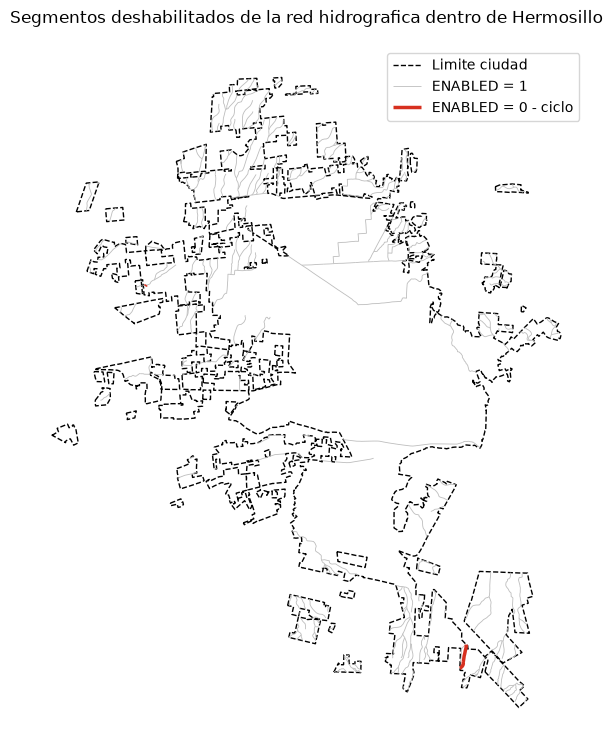

In [33]:
# Mapa: gris = habilitados, rojo = ciclos (C), azul = bifurcaciones (B).
# Dentro de la ciudad no hay 'B', pero el color queda definido por si cambia el recorte.
colores = {1: "#bdbdbd", "C": "#d7301f", "B": "#2c7fb8"}

fig, ax = plt.subplots(figsize=(9, 9))
gpd.GeoSeries([ciudad], crs=METRICO).boundary.plot(
    ax=ax, color="black", linewidth=1, linestyle="--", label="Limite ciudad"
)
hl_ciudad[hl_ciudad["ENABLED"] == 1].plot(
    ax=ax, color=colores[1], linewidth=0.6, label="ENABLED = 1"
)
for valor, etiqueta in [("C", "ENABLED = 0 - ciclo"), ("B", "ENABLED = 0 - bifurcacion")]:
    capa = deshabilitados[deshabilitados["DESC_ENABL"] == valor]
    if not capa.empty:
        capa.plot(ax=ax, color=colores[valor], linewidth=2.5, label=etiqueta)

ax.set_title("Segmentos deshabilitados de la red hidrografica dentro de Hermosillo")
ax.set_axis_off()
ax.legend()
plt.show()

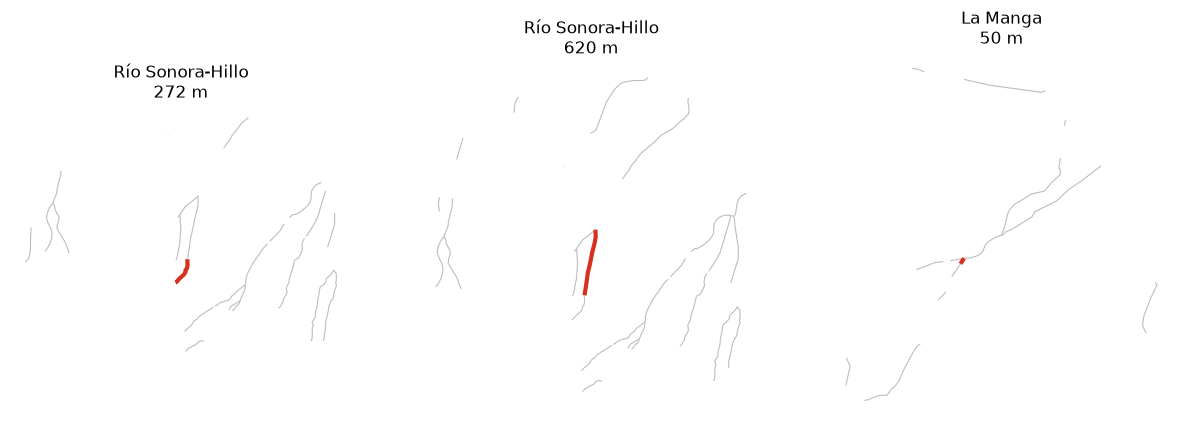

In [34]:
# Zoom a cada segmento deshabilitado (1.5 km de contexto):
# a escala de la ciudad apenas se distinguen (~0.9 km en total).
n = len(deshabilitados)
fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
axes = [axes] if n == 1 else axes
for ax, (_, seg) in zip(axes, deshabilitados.iterrows()):
    entorno = seg.geometry.buffer(1500)
    gpd.clip(hl_ciudad, entorno).plot(ax=ax, color=colores[1], linewidth=0.8)
    gpd.GeoSeries([seg.geometry], crs=METRICO).plot(
        ax=ax, color=colores[seg["DESC_ENABL"]], linewidth=3
    )
    ax.set_title(f"{seg['subcuenca']}\n{seg.geometry.length:.0f} m")
    ax.set_axis_off()
plt.show()

### Resultados

- Dentro de la ciudad hay **437 segmentos** de la red `hl` (~189 km) y solo **3 están deshabilitados** (~0.9 km, 0.7% de los segmentos): dos ciclos en Río Sonora-Hillo (272 m y 620 m) y uno en La Manga (50 m). **No hay bifurcaciones (`B`) dentro del área edificada**; en las subcuencas completas solo existen dos, ambas en La Manga.
- `ENABLED = 0` no significa dato inválido ni ausencia de cauce: es un tramo real que el INEGI excluyó de la red geométrica porque forma un ciclo o una bifurcación, lo que impide calcular la dirección de flujo con modelos acíclicos. Por eso sus indicadores de hidromorfometría valen -1/0.
- Implicación para el análisis: para estudios de conectividad o dirección de flujo estos segmentos deben excluirse (la topología los ignora), pero para análisis espacial de cauces —longitud, intersección con colonias— conviene conservarlos porque el agua sí escurre por ellos.
- En las subcuencas completas, fuera de la ciudad, la proporción es mayor: 550 segmentos deshabilitados (~110 km), sobre todo en La Poza (242) y La Manga (164), en cauces de alta montaña donde los cauces se dividen y reconfluyen con más frecuencia.